<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Hyperparameters & GridSearch - Solution

---

### About
An introduction to optimizing machine learning models with grid search and pipelines in `scikit-learn`.

### Learning Objectives
- Describe what the terms hyperparameters, GridSearch, and pipeline mean.
- Apply `sklearn`'s `GridSearchCV` object.
- Use attributes of the GridSearch object.
- Describe the pitfalls of searching large hyperparameter spaces.
- Build pipelines.

### Notebook Guide

- Imports and Data Setup
- Data SetUp
- Grid Search
- Pipelines
- A Word of Caution on GridSearching
- Alternative: RandomSearchCV

![](https://snag.gy/aYcCt2.jpg)

# Imports and Data Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_absolute_error

In [2]:
# abalone is a marine sea snail 

abalone_colnames = [
    'sex', 'length', 'diameter', 'height', 'whole_weight',
    'shucked_weight', 'viscera_weight', 'shell_weight', 'rings'
]
ab = pd.read_csv('../data/abalone.data', names=abalone_colnames)
ab.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
ab.shape

(4177, 9)

In [4]:
ab.isna().sum()

sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
dtype: int64

### Let's Whiz Through the Boring Parts
Quickly so as to get to the fun parts, I'll:
* Create our `X` and `y`. We'll be doing a kNN, so can't use `sex`.
* Do a train-test split
* Scale our data

In [5]:
X = ab.drop(columns=['sex', 'rings'])
y = ab['rings']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=2022)

sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

# Grid Search
---
> _Friends don't let friends use Grid Search._

Up until now, we've tuned our tuning parameters either automatically using some `sklearn` tech, or via sloppy loops. `sklearn` gives us some fun tools for automating this process in many cases. Let's demonstrate with a simple kNN first.

In [8]:
# Create a KNN regression model
knn = KNeighborsRegressor()

# Define the values of k (number of neighbors) to test
# Tests: 1, 6, 11, 16, ..., 201
pgrid = {
    'n_neighbors': np.arange(1, 202, 5)
}

# Use GridSearchCV to test each value of k using cross-validation
# By default, GridSearchCV uses 5-fold cross-validation
gs = GridSearchCV(
    estimator=knn,
    param_grid=pgrid
)

In [9]:
# Run the GridSearchCV
gs.fit(X_train_sc, y_train);

In [10]:
# Display the chosen number of neighbors
gs.best_params_

{'n_neighbors': 31}

In [11]:
# Return the best model
best_model = gs.best_estimator_
best_model

KNeighborsRegressor(n_neighbors=31)

In [12]:
# Predict on a sample abalone
sample_data = [["M", "0.455", "0.365", "0.095", "0.5140", "0.2245", "0.1010" ,"0.150"]]

abalone_colnames.remove("rings")

sample_df = pd.DataFrame(sample_data, columns=abalone_colnames )
sample_df

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150


In [13]:
# Transform your sample
X_sample_sc = sc.transform(sample_df.drop(columns="sex"))

In [14]:
# Predict
best_model.predict(X_sample_sc)

array([8.32258065])

In [15]:
# Going deeper to GridSearchCV results
gs.cv_results_

{'mean_fit_time': array([0.00205817, 0.00120583, 0.00105   , 0.00073109, 0.00072718,
        0.00071864, 0.00071726, 0.00071907, 0.00071888, 0.00072141,
        0.00071793, 0.0007905 , 0.00087504, 0.00073609, 0.00074058,
        0.00072346, 0.00071616, 0.00071955, 0.00071669, 0.00071597,
        0.00073562, 0.00072637, 0.00071898, 0.00072351, 0.00072494,
        0.00072246, 0.00071807, 0.00075083, 0.0007246 , 0.00072021,
        0.00072112, 0.00072021, 0.0007236 , 0.00071902, 0.00075874,
        0.0007617 , 0.00072551, 0.00072694, 0.00072198, 0.00072474,
        0.0007216 ]),
 'std_fit_time': array([1.30385961e-03, 1.15657106e-04, 2.97284049e-04, 1.48315520e-05,
        1.73702293e-05, 5.97361069e-06, 9.74965839e-06, 3.47797061e-06,
        5.33205442e-06, 3.72543812e-06, 1.25991531e-05, 1.07581543e-04,
        1.57997846e-04, 1.48988531e-05, 2.74433766e-05, 1.67665058e-05,
        6.84954628e-06, 3.88263759e-06, 7.30510791e-06, 4.66228735e-06,
        1.93331449e-05, 4.45428186e-06, 4

In [17]:
# Let's beautiful the results
df_gs = pd.DataFrame(gs.cv_results_)
df_gs.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.002058,0.001304,0.004268,0.002068,1,{'n_neighbors': 1},0.208134,0.143136,0.189533,0.212117,0.234357,0.197455,0.030673,41
1,0.001206,0.000116,0.004579,0.000419,6,{'n_neighbors': 6},0.462631,0.528564,0.490114,0.452478,0.525148,0.491787,0.031189,24
2,0.001050,0.000297,0.004301,0.000435,11,{'n_neighbors': 11},0.509811,0.542607,0.510713,0.489675,0.553135,0.521188,0.023288,9
3,0.000731,0.000015,0.003933,0.000134,16,{'n_neighbors': 16},0.522055,0.554505,0.519089,0.494522,0.558949,0.529824,0.023997,4
4,0.000727,0.000017,0.004279,0.000038,21,{'n_neighbors': 21},0.521562,0.551017,0.520809,0.491308,0.569272,0.530794,0.026958,3


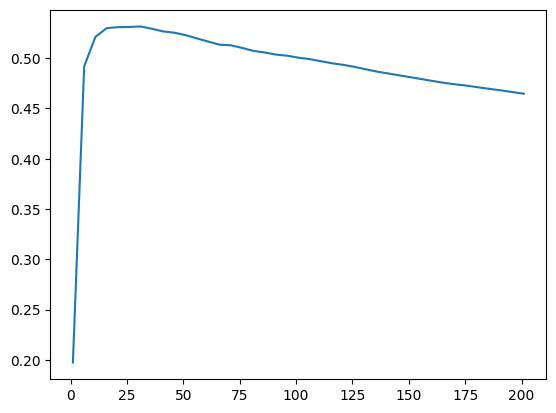

In [18]:
# Plot the relation betweeen number of neighbors and mean test score
plt.plot(df_gs.param_n_neighbors, df_gs.mean_test_score);

This is cool!!! And we actually have `gs.best_estimator_` already fit as our optional model. But there's actually one more piece of efficiency `sklearn` can give us:

## Back to You

Try to find the best `Metric` to use for distance computation.
- You are still using `KNeighborsRegressor`
- You still need to find the best `n_neighbors` at the same time
- Validate your results using mae
- Run 3 folds only

__HINT__: Have a look at [`KNeighborsRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.distance_metrics.html#sklearn.metrics.pairwise.distance_metrics) documentation

In [16]:
#Your Answer Here

In [19]:
# Create a KNN regression model
knn = KNeighborsRegressor()

# Define the parameters to test
pgrid = {
    'n_neighbors': np.arange(1, 202, 5),
    'metric':['euclidean', 'manhattan', 'minkowski']
}

# Use GridSearchCV to test each combination of your parameters
gs = GridSearchCV(
    estimator=knn,
    param_grid=pgrid,
    scoring="neg_mean_absolute_error",
    cv =3
)

In [20]:
# Run the GridSearchCV
gs.fit(X_train_sc, y_train);

In [21]:
# Display the chosen parameters
gs.best_params_

{'metric': 'manhattan', 'n_neighbors': 31}

# Validate vs Evaluate: What's the difference?
---

During **validation**, we are still developing the model. We use `cross-validation` or `GridSearchCV` on the **training set** to check whether the model can generalize to data it was not fitted on and to choose hyperparameters.

Comparing training and validation performance can also help us diagnose the model:

- **Good training, poor validation → likely overfitting**
- **Poor training and poor validation → likely underfitting**
- **Good and similar training/validation performance → better generalization**

Once we are happy with the validation results and have chosen our final model, we use the untouched **test set** for one final evaluation.

**Important:** We should not change the model, hyperparameters, or chosen metric based on the test-set result just to improve the test score. If we repeatedly use the test set to make modeling decisions, the test set becomes part of the model-development process, causing **test-set leakage/contamination** and giving us an overly optimistic estimate of performance.

## Sample Workflow

In [20]:
# Validate your model and look for best parameters

knn = KNeighborsRegressor()

pgrid = {
    'n_neighbors': np.arange(1, 50, 5)
}

gs = GridSearchCV(
    estimator=knn,
    param_grid=pgrid,
    cv=3,
    scoring="neg_mean_absolute_error",
    return_train_score=True
)

In [21]:
gs.fit(X_train_sc, y_train)

GridSearchCV(cv=3, estimator=KNeighborsRegressor(),
             param_grid={'n_neighbors': array([ 1,  6, 11, 16, 21, 26, 31, 36, 41, 46])},
             return_train_score=True, scoring='neg_mean_absolute_error')

In [22]:
# Analyse the results of your gridsearch
df_gs = pd.DataFrame(gs.cv_results_)
df_gs

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,split0_train_score,split1_train_score,split2_train_score,mean_train_score,std_train_score
0,0.002528,1.829313e-03,0.005396,0.002006,1,{'n_neighbors': 1},-1.966475,-2.033525,-1.940613,-1.980204,0.039154,10,-0.000000,-0.000000,-0.000000,0.000000,0.000000
1,0.000980,7.888745e-05,0.005810,0.000864,6,{'n_neighbors': 6},-1.564496,-1.625319,-1.573116,-1.587644,0.026872,9,-1.346025,-1.317289,-1.359515,-1.340943,0.017609
2,0.000667,1.100577e-05,0.005101,0.000071,11,{'n_neighbors': 11},-1.531870,-1.580634,-1.524295,-1.545600,0.024965,8,-1.409222,-1.370472,-1.435780,-1.405158,0.026816
3,0.000648,9.733398e-07,0.005816,0.000039,16,{'n_neighbors': 16},-1.506765,-1.546815,-1.509339,-1.520973,0.018303,1,-1.446360,-1.405232,-1.467583,-1.439725,0.025883
4,0.000680,1.471558e-05,0.006664,0.000171,21,{'n_neighbors': 21},-1.496853,-1.564131,-1.513410,-1.524798,0.028622,4,-1.469987,-1.430327,-1.476510,-1.458941,0.020408
5,0.000698,3.223915e-05,0.007281,0.000079,26,{'n_neighbors': 26},-1.491269,-1.564876,-1.521736,-1.525960,0.030198,5,-1.483993,-1.430887,-1.484122,-1.466334,0.025065
6,0.000678,2.589962e-05,0.007975,0.000020,31,{'n_neighbors': 31},-1.489155,-1.567050,-1.517365,-1.524523,0.032201,3,-1.494778,-1.439655,-1.498780,-1.477738,0.026978
7,0.000641,1.276523e-06,0.008611,0.000030,36,{'n_neighbors': 36},-1.488080,-1.568247,-1.515459,-1.523929,0.033272,2,-1.498404,-1.452573,-1.502621,-1.484532,0.022664
8,0.000643,4.899036e-07,0.009237,0.000114,41,{'n_neighbors': 41},-1.490749,-1.574666,-1.517078,-1.527497,0.035042,6,-1.508153,-1.460121,-1.507593,-1.491956,0.022512
9,0.000697,2.073648e-05,0.010142,0.000088,46,{'n_neighbors': 46},-1.489172,-1.581230,-1.526195,-1.532199,0.037822,7,-1.515138,-1.465319,-1.515763,-1.498740,0.023633


In [23]:
gs.best_params_

{'n_neighbors': 16}

In [24]:
# Extract the index of the best score
gs.best_index_

3

In [25]:
train_score = gs.cv_results_['mean_train_score'][gs.best_index_]
train_score

-1.43972501596424

In [26]:
validation_score = gs.cv_results_['mean_test_score'][gs.best_index_]
validation_score # "test" here means validation fold

-1.5209730204342273

In [27]:
# Evaluate your model
best_model = gs.best_estimator_

y_pred = best_model.predict(X_test_sc)

mean_absolute_error(y_test,y_pred)

1.6270933014354068

# A Word of Caution on GridSearching

`sklearn` models often have many hyperparameters with many different possible values. It may be tempting to search over a wide variety of them. In general, this is not wise.

<details><summary>Why not?</summary>

- Remember that GridSearch searches over **all possible combinations of hyperparameters in the parameter dictionary!**

Imagine that we had this as our parameter dictionary:

```python
parameter_grid = {
    'n_neighbors': range(1, 151),
    'weights': ['uniform', 'distance', custom_function],
    'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],
    'leaf_size': range(1, 152),
    'metric': ['minkowski', 'euclidean'],
    'p': [1, 2]
}
```

**How many different combinations will need to be tested?**

| Parameter | Number of Chosen Values |
| --- | --- |
| **n_neighbors** | 150 |
| **weights** | 3 |
| **algorithm** | 4 |
| **leaf_size** | 151 |
| **metric** | 2 |
| **p** | 2 |
| <br>_150 \* 3 \* 4 \* 151 \* 2 \* 2 = n combinations_ <br><br>| _1,087,200_ |

If we select `cv = 5`, we would fit 1,087,200 models on five folds, meaning we fit 5,436,000 models!

If you're not careful, GridSearching can quickly scale out of hand computationally.

> **It is extremely important to understand what the hyperparameters do and think critically about what ranges are useful and relevant to your model!**
</details>

## Alternative: `RandomSearchCV`
**Random searching** (aka **stochastic searching**) is a much more recommended method for large parameter spaces. It choses tuning parameter combinations at random to "visit" more of the parameter space without doing an exhaustive search.

Have a look at the visuals in this [article](https://www.geeksforgeeks.org/machine-learning/hyperparameter-tuning)

In [28]:
from sklearn.model_selection import RandomizedSearchCV

# Interview Question

<details><summary>What is the difference between hyperparameters and statistical parameters?</summary>
    
- Statistical parameters are quantities that a model can learn or estimate. Examples include $\beta_0$ and $\beta_1$ in a linear model.
- Hyperparameters are quantities our model cannot learn, but affect the fit of our model. Examples include $k$ in $k$-nearest neighbors and $alpha$ in regularization.
</details>

---

To the slides!

---